# Estado del arte: árboles penalizados, boosting transparente, boosting monótono y un modelo fundacional frente a la tarjeta de puntaje

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 01 a 05 de este tema
- **Tiempo de lectura:** unos 70 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar a los retadores actuales de una tarjeta de puntaje WoE en scoring de crédito (árboles penalizados, boosting explicable, gradient boosting monótono, un modelo fundacional tabular), qué afirma cada uno y la fuente de la afirmación;
- compararlos con la tarjeta de puntaje sobre las mismas 9.000 tarjetas reservadas con el AUC, la prueba de DeLong pareada, el puntaje de Brier, el error de calibración y el chi-cuadrado sobre grados, y recalcular las comparaciones versionadas;
- abrir los componentes transparentes de los modelos versionados: las reglas de los árboles penalizados y su estabilidad, las funciones de forma de la máquina de boosting y las restricciones monótonas de los árboles con boosting;
- leer lo que hizo la calibración isotónica a cada retador, y qué cambia en una muestra pequeña (los 300 registros alemanes y un ajuste de 2.000 filas), donde aparece el modelo fundacional.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

La comparación lee cinco archivos versionados del caso C01 (PD de tarjetas de crédito minoristas):

- `data/derived/C01/holdout.json`: la escalera sobre las 9.000 tarjetas reservadas de Taiwán (UCI Taiwán, Yeh 2009, CC BY 4.0, clase de licencia `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients): el AUC, los grados, los tramos de confiabilidad antes y después de calibrar, y la batería de pruebas.
- `data/derived/C01/models-taiwan.json`: lo que aprendió cada modelo (reglas, funciones de forma, restricciones, mapas de calibración).
- `data/derived/C01/small-sample.json`: las mismas tarjetas puntuadas por modelos ajustados con solo 2.000 filas.
- `data/derived/C01/german-twin.json` y `data/derived/C01/models-german.json`: los datos de crédito alemanes Statlog (1.000 registros, UCI, CC BY 4.0, clase de licencia `mirror-allowed`, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data), con una muestra reservada de 300, donde también está el modelo fundacional P5.

Todo se lee, nada se reajusta: los retadores necesitan `interpret`, `lightgbm`, `xgboost` (y `tabpfn` para P5) además de `scikit-learn`, y el entorno de los cuadernos no los trae (tiene `scikit-learn`, para las referencias del tema 13, pero no el resto); sus versiones son las registradas en el ajuste versionado. La siguiente celda carga los archivos e imprime la escalera con el motor, la versión y la licencia de cada modelo.

In [2]:
# Cargar los archivos versionados e imprimir la escalera con el motor, la versión y la licencia de cada modelo
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
read = lambda name: json.loads((derived / name).read_text(encoding="utf-8"))
holdout, models, small, german_twin, models_german = (read(n) for n in ("holdout.json", "models-taiwan.json", "small-sample.json", "german-twin.json", "models-german.json"))

LANG = "es"
# Los valores de luz del motor, nombrados en este idioma
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "s/l"}
for m in models["model"]:
    print(f"{m['id']:14s} {m['engine_version'][:36]:36s} {m['licence'][:40]}")
print("calculado por riskvalidation", holdout["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)


P0-constant    n/a                                  MIT
P0-single      1.0.0                                Apache-2.0
P1-scorecard   optbinning 1.0.0, statsmodels 0.15.0 Apache-2.0, BSD-3-Clause
P2a-l1         1.9.1                                BSD-3-Clause
P2b-pltr       1.9.1                                BSD-3-Clause
P3-ebm         0.7.8                                MIT
P4-lightgbm    4.7.0                                MIT
P4-xgboost     3.4.1                                Apache-2.0
calculado por riskvalidation 0.4.3 | instalado 0.9.0


## Método

### El protocolo de la comparación

Cada retador se juzga sobre las mismas 9.000 tarjetas con la misma batería, de modo que una diferencia sea propiedad del modelo y no de la muestra. Tres mediciones deciden, y cada una tiene su herramienta en el motor:

- **ordenamiento**: el AUC, y para dos modelos puntuados sobre las mismas tarjetas la prueba de DeLong pareada del cuaderno 03, cuyo estadístico z es la diferencia de AUC sobre su error estándar (DeLong, DeLong y Clarke-Pearson, 1988);
- **calidad del pronóstico**: el puntaje de Brier, el error cuadrático medio de la PD como pronóstico del resultado 0/1, y el error de calibración esperado sobre $B$ tramos, $\mathrm{ECE} = \sum_b (n_b/N)\,|\overline{\mathrm{PD}}_b - \mathrm{DR}_b|$, la brecha media ponderada entre la PD media y la tasa de incumplimiento observada de un tramo;
- **el ajuste por grado**: el chi-cuadrado sobre los grados de la escala maestra (documento de trabajo 14 del BCBS), que el motor calcula desde los conteos, incumplimientos y PD media de cada grado.

La siguiente celda verifica la fórmula del ECE sobre los tramos de confiabilidad versionados de la tarjeta de puntaje, contra el valor versionado del motor, y luego llama al chi-cuadrado sobre grados del motor sobre la tabla de grados versionada de cada modelo y lo compara con la fila versionada. Después imprime la tabla común de la escalera: AUC, la comparación pareada con la tarjeta de puntaje, Brier, ECE y el valor p del chi-cuadrado.

In [3]:
# Verificar la fórmula del ECE, llamar al chi-cuadrado sobre grados del motor en cada modelo e imprimir la tabla común de la escalera
from riskvalidation.validation import pd_chi2_grades

policy = rv.default_policy()
tests = holdout["tests"]


def row(test_id, model_id, doc=holdout, segment="portfolio"):
    return next((t for t in doc["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == segment), None)


def ece_of(bins_):
    total = sum(b["n"] for b in bins_)
    return sum(b["n"] * abs(b["pd"] - b["dr"]) for b in bins_) / total


p1_bins = holdout["outputs"]["rungs"]["P1-scorecard"]["reliability"]
print("ECE desde los tramos de la tarjeta de puntaje:", round(ece_of(p1_bins), 6), "| versionado:", round(row("pd.ece", "P1-scorecard")["metric"], 6))
print()
rungs = [m["id"] for m in holdout["model"]]
print(f"{'modelo':14s} {'AUC':>7s} {'z vs P1':>9s} {'p DeLong':>10s} {'Brier':>7s} {'ECE':>7s} {'p chi2 motor':>16s} {'versionado':>10s} {'luz':>6s}")
for r in rungs:
    grades = [g for g in holdout["outputs"]["rungs"][r]["grades"] if g["n"] > 0]
    chi = pd_chi2_grades([g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades], policy=policy, model_id=r, segment="portfolio")
    chi_row = row("pd.chi2_grades", r)
    dl = row("disc.delong", r)
    z = "-" if dl is None else f"{dl['statistic']:.2f}"
    p_dl = "-" if dl is None else f"{dl['p_value']:.3g}"
    committed_p = "-" if chi_row is None else f"{chi_row['p_value']:.3g}"
    light_text = "-" if chi_row is None else LIGHT[chi_row["light"]]
    print(f"{r:14s} {row('disc.auc', r)['metric']:7.4f} {z:>9s} {p_dl:>10s} {row('pd.brier', r)['metric']:7.4f} {row('pd.ece', r)['metric']:7.4f} {chi.p_value:16.3g} {committed_p:>10s} {light_text:>6s}")


ECE desde los tramos de la tarjeta de puntaje: 0.015501 | versionado: 0.015501

modelo             AUC   z vs P1   p DeLong   Brier     ECE     p chi2 motor versionado    luz
P0-constant     0.5000         -          -  0.1723  0.0174            0.994          -      -
P0-single       0.6917    -13.35   1.26e-40  0.1431  0.0144            0.598      0.598  verde
P1-scorecard    0.7587         -          -  0.1393  0.0155           0.0264     0.0264  ámbar
P2a-l1          0.7587     -1.70     0.0884  0.1393  0.0153           0.0405     0.0405  ámbar
P2b-pltr        0.7749      6.67   2.58e-11  0.1367  0.0113            0.464      0.464  verde
P3-ebm          0.7746      6.31   2.74e-10  0.1367  0.0118                0          0   rojo
P4-lightgbm     0.7770      7.19   6.53e-13  0.1361  0.0134         0.000672   0.000672   rojo
P4-xgboost      0.7755      7.02   2.18e-12  0.1359  0.0124                0          0   rojo


## Estado del arte

### La evidencia de los estudios comparativos

La investigación de este producto (dossier 04, sección B.4) leyó los estudios comparativos de scoring de crédito. Cuatro hallazgos enmarcan la comparación; cada uno lleva su fuente:

| Fuente | Diseño | Hallazgo relevante aquí |
|---|---|---|
| Baesens et al. (2003), https://doi.org/10.1057/palgrave.jors.2601545 | 8 conjuntos de datos de crédito reales, AUC y exactitud con pruebas de significancia | las máquinas de vectores de soporte y las redes neuronales funcionan muy bien, y la regresión logística simple y el análisis discriminante lineal también funcionan muy bien |
| Lessmann, Baesens, Seow y Thomas (2015), https://doi.org/10.1016/j.ejor.2015.05.030 | 41 clasificadores, 8 conjuntos de datos minoristas, seis medidas | varios clasificadores superan significativamente a la regresión logística, en especial los ensambles heterogéneos; el bosque aleatorio es el referente mínimo recomendado; reportar al menos el AUC, el Gini parcial y el puntaje de Brier |
| Gunnarsson et al. (2021), https://doi.org/10.1016/j.ejor.2021.03.006 | perceptrón multicapa y red de creencia profunda frente a regresión logística, árboles, bosque aleatorio y XGBoost | XGBoost es el mejor método, y las redes profundas no superan a sus contrapartes más someras |
| Grinsztajn, Oyallon y Varoquaux (2022), https://arxiv.org/abs/2207.08815 | 45 conjuntos de datos tabulares generales (no específicos de crédito) | los modelos basados en árboles siguen siendo el estado del arte en datos de tamaño medio, de unas 10.000 muestras |

La síntesis que sacó la investigación, y que sigue la escalera del producto: los ensambles de árboles superan a la regresión logística simple en la mayoría de los estudios minoristas, por unos pocos puntos de AUC; la regresión logística sobre WoE bien agrupado sigue siendo competitiva; la interpretabilidad puede recuperarse con modelos restringidos o transparentes, que son los retadores naturales de un modelo de PD regulado; y la calibración es una propiedad separada de la discriminación. La siguiente celda alinea el AUC versionado de cada escalón con la ganancia sobre la tarjeta de puntaje, su intervalo del 95% y el valor p de DeLong pareado, y la figura lo dibuja.

modelo             AUC intervalo del 95% ganancia vs P1   p DeLong
P0-constant     0.5000   0.500-0.500        -0.2587          -
P0-single       0.6917   0.679-0.705        -0.0670   1.26e-40
P1-scorecard    0.7587   0.746-0.771        +0.0000          -
P2a-l1          0.7587   0.746-0.771        -0.0000     0.0884
P2b-pltr        0.7749   0.763-0.787        +0.0162   2.58e-11
P3-ebm          0.7746   0.763-0.787        +0.0159   2.74e-10
P4-lightgbm     0.7770   0.765-0.789        +0.0183   6.53e-13
P4-xgboost      0.7755   0.763-0.787        +0.0168   2.18e-12


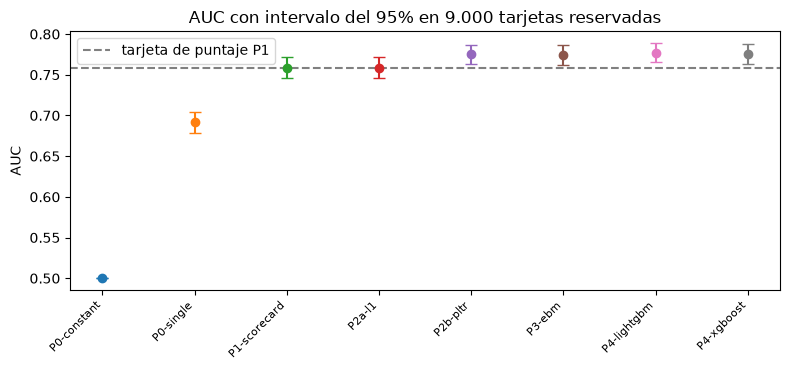

In [4]:
# Alinear el AUC de cada escalón con su ganancia sobre la tarjeta de puntaje y el valor p de DeLong pareado, y dibujarlo
base = row("disc.auc", "P1-scorecard")["metric"]
print(f"{'modelo':14s} {'AUC':>7s} {'intervalo del 95%':>16s} {'ganancia vs P1':>14s} {'p DeLong':>10s}")
for r in rungs:
    a = row("disc.auc", r)
    dl = row("disc.delong", r)
    p_text = "-" if dl is None else f"{dl['p_value']:.3g}"
    print(f"{r:14s} {a['metric']:7.4f} {a['extras']['ci95_low']:7.3f}-{a['extras']['ci95_high']:.3f} {a['metric'] - base:+14.4f} {p_text:>10s}")

fig, ax = plt.subplots(figsize=(8, 3.8))
for i, r in enumerate(rungs):
    a = row("disc.auc", r)
    ax.errorbar(i, a["metric"], yerr=[[a["metric"] - a["extras"]["ci95_low"]], [a["extras"]["ci95_high"] - a["metric"]]], fmt="o", capsize=4)
ax.axhline(base, color="gray", linestyle="--", label="tarjeta de puntaje P1")
ax.set_xticks(range(len(rungs)))
ax.set_xticklabels(rungs, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("AUC")
ax.set_title("AUC con intervalo del 95% en 9.000 tarjetas reservadas")
ax.legend()
fig.tight_layout()
plt.show()


### Árboles penalizados (PLTR) y la regresión logística penalizada

Dumitrescu, Hue, Hurlin y Tokpavi (2022, https://doi.org/10.1016/j.ejor.2021.06.053) proponen la **regresión logística de árboles penalizada**: se hacen crecer árboles de decisión cortos, cada camino de la raíz a un nodo se vuelve una regla binaria (como "`PAY_0 <= 1.5`"), y las reglas entran en una regresión logística con penalización L1 que conserva pocas. El resumen de la investigación informa que supera significativamente a la regresión logística y es competitiva con un bosque aleatorio conservando la legibilidad de un modelo logístico. El escalón P2b del producto sigue ese diseño con árboles de scikit-learn y `LogisticRegression`, con extracción de reglas propia; el escalón P2a es la regresión logística L1 simple sobre las variables WoE. La siguiente celda lee lo que conservaron los ajustes versionados: cuántas reglas candidatas generó P2b y cuántas sobrevivieron a la penalización, sus primeras reglas con sus coeficientes, y la estabilidad del conjunto de reglas en 20 remuestreos bootstrap (el índice de Jaccard medio de los conjuntos de reglas seleccionados, 1 para conjuntos idénticos), junto con los coeficientes de P2a frente a los de la tarjeta de puntaje.

In [5]:
# Leer las reglas conservadas por P2b, su estabilidad entre bootstraps y los coeficientes de P2a frente a la tarjeta de puntaje
details = {m["id"]: m["details"] for m in models["model"]}
pltr = details["P2b-pltr"]
print("reglas candidatas:", pltr["n_candidate_rules"], "| reglas conservadas por la penalización L1:", len(pltr["selected_rules"]))
for rule in pltr["selected_rules"][:6]:
    print(f"  {rule['coefficient']:8.3f}  {rule['rule'].replace(' and ', ' y ')}")
st = pltr["stability"]
print("índice de Jaccard de los conjuntos seleccionados en", st["bootstraps"], "bootstraps: media", round(st["jaccard_mean"], 3), "| mínimo", round(st["jaccard_min"], 3))
l1, card = details["P2a-l1"], details["P1-scorecard"]
gap = max(abs(l1["coefficients"][v] - card["coefficients"][v]) for v in card["features"])
print("P2a: variables conservadas", len(l1["selected"]), "| los signos concuerdan con el WoE:", si_no(l1["signs_agree_with_woe"]), "| mayor brecha de coeficientes con la tarjeta de puntaje:", round(gap, 4))


reglas candidatas: 449 | reglas conservadas por la penalización L1: 101
     0.302  LIMIT_BAL <= 145000
    -1.270  PAY_0 <= 1.5
     0.035  BILL_AMT5 <= 50602
     0.023  PAY_AMT5 <= 2926.5
     0.108  PAY_AMT6 <= 2305.5
     0.147  LIMIT_BAL <= 145000 y LIMIT_BAL <= 45000
índice de Jaccard de los conjuntos seleccionados en 20 bootstraps: media 0.411 | mínimo 0.367
P2a: variables conservadas 13 | los signos concuerdan con el WoE: sí | mayor brecha de coeficientes con la tarjeta de puntaje: 0.0019


### Boosting explicable (EBM y GA2M)

El modelo aditivo generalizado con interacciones de a pares (GA2M, Lou, Caruana, Gehrke y Hooker, 2013, https://doi.org/10.1145/2487575.2487579) y su implementación con boosting, la máquina de boosting explicable (Nori, Jenkins, Koch y Caruana, 2019, https://arxiv.org/abs/1909.09223), modelan el logaritmo de las probabilidades relativas como una suma de funciones de una variable y unos pocos términos de a pares:

$$g(\mathbb{E}[y]) = \beta_0 + \sum_j f_j(x_j) + \sum_{(i,j)} f_{ij}(x_i, x_j)$$

con $g$ el enlace logit y cada $f_j$ aprendida por gradient boosting cíclico con una tasa de aprendizaje muy baja. El resumen de la investigación anota la consecuencia para el crédito: una EBM es una tarjeta de puntaje con boosting, pues cada $f_j$ puede leerse como una tabla de puntos y los códigos de razón de los efectos principales son exactos. El ajuste versionado exporta los términos. La siguiente celda lee la función de forma del límite de crédito y del estado de pago del último mes desde la exportación, y las pone junto a la contribución propia de la tarjeta de puntaje al logaritmo de las probabilidades relativas en los mismos tramos, $\beta_j\,\mathrm{WoE}_{j,b}$ (cuaderno 01). Ambas se desplazan para que su nivel más bajo sea cero, porque las constantes aditivas viven en el intercepto.

términos de efecto principal: 20 | términos de a pares: 5 | ['BILL_AMT1 & BILL_AMT2', 'BILL_AMT1 & BILL_AMT3'] ...


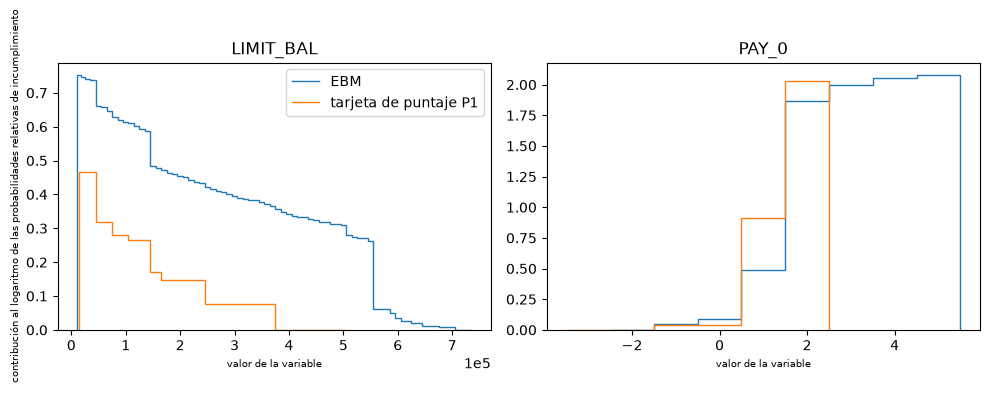

PAY_0 EBM niveles: [-0.32, -0.26, -0.23, 0.18, 1.55, 1.68, 1.74, 1.76]
PAY_0 tarjeta de puntaje: [-0.47, -0.43, 0.43, 1.55]


In [6]:
# Leer dos funciones de forma de la exportación de la EBM y compararlas con la contribución de la tarjeta de puntaje en sus propios tramos
export = details["P3-ebm"]["export"]
term_names = [t["name"] for t in export["terms"]]
main_terms = [t for t in export["terms"] if len(t["features"]) == 1]
pair_terms = [t for t in export["terms"] if len(t["features"]) == 2]
print("términos de efecto principal:", len(main_terms), "| términos de a pares:", len(pair_terms), "|", [t["name"] for t in pair_terms][:2], "...")


def ebm_steps(name):
    # El intervalo de cada puntaje está entre dos puntos de corte; el primer y el último puntaje son los tramos faltante y no visto
    term = next(t for t in main_terms if t["name"] == name)
    cuts = next(f for f in export["features"] if f["name"] == name)["levels"][0]["cuts"]
    return np.array(cuts), np.array(term["scores"][1:-1])


def card_steps(name):
    rows = [r for r in card["points_table"] if r["feature"] == name and r["count"] > 0]
    return np.array(card["bins"][name]["splits"]), np.array([card["coefficients"][name] * r["woe"] for r in rows])


fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    cuts_e, scores_e = ebm_steps(name)
    cuts_c, scores_c = card_steps(name)
    for cuts_, scores_, label in ((cuts_e, scores_e, "EBM"), (cuts_c, scores_c, "tarjeta de puntaje P1")):
        # Un valor por intervalo: los bordes son los puntos de corte más un borde exterior a cada lado
        edges = np.r_[cuts_[0] - (cuts_[1] - cuts_[0]) if len(cuts_) > 1 else cuts_[0] - 1, cuts_, cuts_[-1] + (cuts_[-1] - cuts_[-2]) if len(cuts_) > 1 else cuts_[-1] + 1]
        ax.stairs(scores_ - scores_.min(), edges, label=label)
    ax.set_title(name)
    ax.set_xlabel("valor de la variable", fontsize=7)
    if name == "LIMIT_BAL":
        ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0].set_ylabel("contribución al logaritmo de las probabilidades relativas de incumplimiento", fontsize=7)
axes[0].legend()
fig.tight_layout()
plt.show()
print("PAY_0 EBM niveles:", [round(float(s), 2) for s in ebm_steps("PAY_0")[1]])
print("PAY_0 tarjeta de puntaje:", [round(float(s), 2) for s in card_steps("PAY_0")[1]])


### Gradient boosting monótono

Los árboles con gradient boosting (LightGBM, XGBoost, CatBoost) aceptan una restricción monótona por variable, la misma dirección que la tarjeta de puntaje impone con su agrupación. La documentación de cada motor declara las salvedades que la investigación registró: con los métodos de árbol `hist` o `approx`, las restricciones de XGBoost pueden eliminar candidatos de división y dar árboles poco profundos (https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html); LightGBM ofrece los métodos `basic`, `intermediate` y `advanced`, de los cuales `basic` restringe de más las predicciones (https://lightgbm.readthedocs.io/en/latest/Parameters.html); y el `monotonize()` de la EBM se aplica después del ajuste, a un término a la vez. El ajuste versionado de LightGBM usa el método `advanced` con las mismas restricciones que la tarjeta de puntaje, y el artefacto guarda una verificación: la curva de dependencia parcial del modelo a lo largo de una grilla de cada variable restringida, con la mayor violación de la restricción encontrada. La siguiente celda compara las restricciones versionadas con las de la tarjeta de puntaje, imprime las violaciones y dibuja las curvas de dos variables.

las restricciones son iguales a las de la tarjeta de puntaje: sí | método: advanced | árboles: 94
variables verificadas: 13 | mayor violación encontrada: 0.0 | monótono: sí


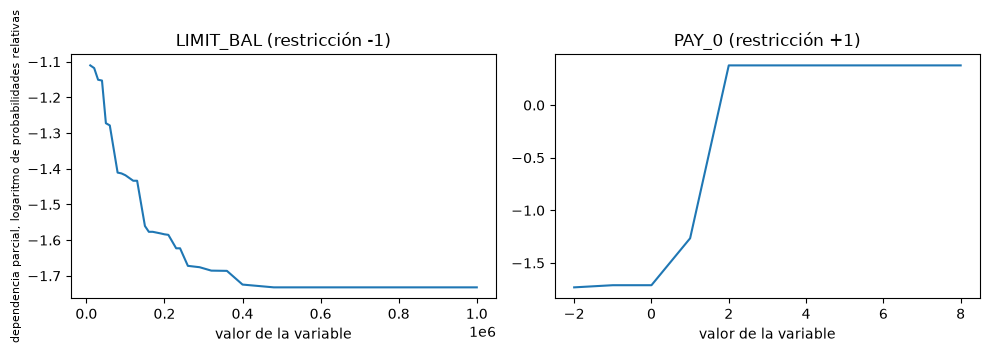

In [7]:
# Comparar las restricciones versionadas con las de la tarjeta de puntaje, imprimir las violaciones y dibujar dos curvas de dependencia parcial
lgbm = details["P4-lightgbm"]
scorecard_directions = {v["name"]: v["monotone"] for v in models["fit"]["features"]}
same = all(lgbm["constraints"][k] == scorecard_directions[k] for k in scorecard_directions)
print("las restricciones son iguales a las de la tarjeta de puntaje:", si_no(same), "| método:", lgbm["params"]["monotone_constraints_method"], "| árboles:", lgbm["rounds"])
check = lgbm["monotonicity"]
print("variables verificadas:", len(check["features"]), "| mayor violación encontrada:", max(f["max_violation"] for f in check["features"].values()), "| monótono:", si_no(check["monotone"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    f = check["features"][name]
    ax.plot(f["grid"], f["pdp"])
    ax.set_title(f"{name} (restricción {f['direction']:+d})")
    ax.set_xlabel("valor de la variable")
axes[0].set_ylabel("dependencia parcial, logaritmo de probabilidades relativas", fontsize=8)
fig.tight_layout()
plt.show()


### Calibración después del ordenamiento

Discriminación y calibración son propiedades separadas: un modelo puede ordenar bien y dar PD de tamaño equivocado. Dos advertencias de la investigación aplican. Corregir un desbalance de clases remuestreando (submuestreo o sobremuestreo aleatorio, SMOTE) produce modelos fuertemente descalibrados, con la probabilidad de la clase minoritaria sobreestimada, sin un AUC mayor (van den Goorbergh, van Smeden, Timmerman y Van Calster, 2022, https://doi.org/10.1093/jamia/ocac093); cuando una muestra se balancea por diseño, el intercepto debe corregirse por la probabilidad a priori (King y Zeng, 2001, https://doi.org/10.1093/oxfordjournals.pan.a004868). C01 no remuestrea nada: su tasa de incumplimiento es 22%, y los retadores conservan la distribución de entrenamiento. Lo que hace el producto es ajustar un **mapa de calibración posterior** en un tramo de tarjetas que ni el ajuste ni la prueba han visto, la regresión isotónica (Zadrozny y Elkan, 2002, https://doi.org/10.1145/775047.775151), una función escalonada monótona que no puede reordenar las tarjetas. Los tramos de confiabilidad del artefacto se guardan antes del mapa (`reliability_raw`) y después (`reliability`), de modo que su efecto puede medirse con la fórmula del ECE verificada arriba.

In [8]:
# Medir el ECE de los retadores antes y después del mapa isotónico, desde los tramos de confiabilidad guardados
print(f"{'modelo':14s} {'mapa':>10s} {'ajustado en':>22s} {'ECE antes':>12s} {'ECE después':>12s} {'ECE versionado':>16s}")
for m in models["model"]:
    if m["calibration"] is None:
        continue
    r = m["id"]
    rung_bins = holdout["outputs"]["rungs"][r]
    print(f"{r:14s} {m['calibration']['kind']:>10s} {'tramo de calibración':>22s} {ece_of(rung_bins['reliability_raw']):12.4f} {ece_of(rung_bins['reliability']):12.4f} {row('pd.ece', r)['metric']:16.4f}")
print("puntos del mapa isotónico de P3:", len(next(m for m in models["model"] if m["id"] == "P3-ebm")["calibration"]["x"]))


modelo               mapa            ajustado en    ECE antes  ECE después   ECE versionado
P3-ebm           isotonic   tramo de calibración       0.0218       0.0118           0.0118
P4-lightgbm      isotonic   tramo de calibración       0.0121       0.0134           0.0134
P4-xgboost       isotonic   tramo de calibración       0.0131       0.0124           0.0124
puntos del mapa isotónico de P3: 58


### Datos pequeños y el modelo fundacional

Los modelos fundacionales tabulares son la frontera abierta de la investigación, más fuertes en datos pequeños (Hollmann et al., 2025, https://doi.org/10.1038/s41586-024-08328-6): TabPFN predice por aprendizaje en contexto y no entrena nada por conjunto de datos. Su licencia es parte de la evidencia. Según la investigación (leída del README del proyecto, https://github.com/PriorLabs/TabPFN, el 2026-10-04), el código es Apache-2.0 mientras que los pesos tienen licencia por versión: los de v2 bajo la Prior Labs License v1.1 (Apache 2.0 más una cláusula de atribución), los de las versiones posteriores bajo una licencia no comercial que permite investigación y evaluación interna pero no uso en producción. Por eso el producto lo lleva como **retador de investigación** opcional (escalón P5), presente solo donde su extra está instalado. La evidencia específica de crédito encontrada es un resumen de congreso con resultados preliminares y sin números (SIN VERIFICAR más allá del resumen). El gemelo alemán versionado tiene 1.000 registros y una muestra reservada de 300, el caso de datos pequeños. La siguiente celda imprime la licencia versionada de P5, y para los 300 registros alemanes y para las 9.000 tarjetas de Taiwán puntuadas por modelos ajustados con 2.000 filas, el AUC de cada escalón con el valor p de DeLong pareado contra la tarjeta de puntaje y la luz de Hosmer-Lemeshow.

In [9]:
# Imprimir la licencia de P5 y las comparaciones de datos pequeños: 300 registros alemanes y modelos ajustados con 2.000 filas
p5 = next(m for m in models_german["model"] if m["id"] == "P5-tabpfn")
assert "Apache-2.0" in p5["licence"] and "Prior Labs License v1.1" in p5["licence"]
print("P5 motor:", p5["engine"], p5["engine_version"], "| licencia del código: Apache-2.0 | pesos: TabPFN v2, Prior Labs License v1.1 (atribución requerida)")
for title, doc in (("Gemelo alemán, muestra reservada de 300 registros", german_twin), ("Tarjetas de Taiwán, modelos ajustados con 2000 filas", small)):
    print()
    print(title, "|", doc["outputs"]["n"], "tarjetas, incumplimientos", doc["outputs"]["defaults"])
    print(f"{'modelo':14s} {'AUC':>7s} {'p DeLong':>10s} {'p HL':>10s} {'luz HL':>10s}")
    for m in doc["model"]:
        r = m["id"]
        if r in ("P0-constant",):
            continue
        a = row("disc.auc", r, doc)
        dl = row("disc.delong", r, doc)
        hl = row("pd.hosmer_lemeshow", r, doc)
        print(f"{r:14s} {a['metric']:7.4f} {'-' if dl is None else format(dl['p_value'], '.3g'):>10s} {format(hl['p_value'], '.3g'):>10s} {LIGHT[hl['light']]:>10s}")


P5 motor: tabpfn 9.1.0 | licencia del código: Apache-2.0 | pesos: TabPFN v2, Prior Labs License v1.1 (atribución requerida)

Gemelo alemán, muestra reservada de 300 registros | 300 tarjetas, incumplimientos 90
modelo             AUC   p DeLong       p HL     luz HL
P0-single       0.7233     0.0189      0.328      verde
P1-scorecard    0.7883          -      0.876      verde
P2a-l1          0.7908      0.124      0.654      verde
P2b-pltr        0.7861       0.87      0.597      verde
P3-ebm          0.7874      0.955   4.11e-14       rojo
P4-lightgbm     0.7784      0.615          0       rojo
P5-tabpfn       0.7769      0.488          0       rojo

Tarjetas de Taiwán, modelos ajustados con 2000 filas | 9000 tarjetas, incumplimientos 1991
modelo             AUC   p DeLong       p HL     luz HL
P0-single       0.6928   5.33e-38      0.101      verde
P1-scorecard    0.7525          -    3.5e-05       rojo
P2a-l1          0.7511     0.0737     0.0097       rojo
P2b-pltr        0.7528    

## Resultados

- **En 9.000 tarjetas de Taiwán los modelos más ricos ordenan mejor, por unos pocos puntos de AUC.** Los árboles con boosting monótono llegan a 0,777 (LightGBM) y 0,775 (XGBoost) frente a 0,759 de la tarjeta de puntaje, y los árboles penalizados y la máquina de boosting a 0,775; el valor p de DeLong pareado es menor que 1e-9 en los cuatro, y la regresión logística penalizada empata con la tarjeta de puntaje (p 0,09). Ese es el tamaño que reportaron los estudios comparativos (unos pocos puntos): una ganancia de 0,016 a 0,018 puntos de AUC.
- **El ajuste por grado no sigue al ordenamiento.** El chi-cuadrado sobre grados es rojo para la máquina de boosting y los dos escalones con boosting y ámbar para la tarjeta de puntaje y P2a, mientras que los árboles penalizados están en verde. El motor devuelve el valor p versionado desde cada tabla de grados. Un mejor ordenador no es un modelo mejor calibrado.
- **Las cajas transparentes se abren.** Los árboles penalizados conservaron 101 de 449 reglas candidatas, pero el conjunto de reglas es inestable entre bootstraps (Jaccard medio cerca de 0,41), lo que limita cuánto puede apoyarse un lector en una regla. Las funciones de forma de la máquina de boosting explicable para el límite de crédito y el estado de pago tienen la misma dirección y una forma escalonada parecida a las contribuciones de la tarjeta de puntaje, y sus 5 términos de a pares están todos entre los montos de cuenta. Los árboles con boosting obedecen sus restricciones monótonas: las verificaciones guardadas con el ajuste no encuentran ninguna violación.
- **La calibración ayuda cuando se necesita.** El mapa isotónico reduce a la mitad el ECE de la máquina de boosting (0,022 a 0,012), cambia los árboles con boosting en cerca de una milésima (0,012 a 0,013 para LightGBM, un leve empeoramiento), y no puede reordenar tarjetas. Un mapa de calibración es una herramienta, no una garantía, y su efecto se mide, no se supone.
- **En datos pequeños la ventaja desaparece.** En los 300 registros alemanes ningún retador supera significativamente a la tarjeta de puntaje (p de DeLong de 0,12 a 0,96, y 0,61 para LightGBM); el modelo fundacional P5 llega a un AUC de 0,777 frente a 0,788 de la tarjeta de puntaje, con el menor ECE de la escalera (0,039 frente a 0,045), y la máquina de boosting, LightGBM y P5 están en rojo en Hosmer-Lemeshow. Con modelos ajustados con 2.000 filas la máquina de boosting sí supera a la tarjeta de puntaje (p 0,0005), una ganancia de 0,012 puntos de AUC.

Lo que este cuaderno no muestra: el ajuste de los retadores (`data-pipeline/pipeline/model/` del producto, con las librerías fijadas en `data-pipeline/requirements.txt`), una comparación directa con un bosque aleatorio (la investigación lo recomienda como referente mínimo; la escalera no tiene un escalón de bosque aleatorio), ni evidencia fuera del tiempo: C01 es una sola foto, y el cuaderno 04 es donde se muestra el diseño fuera del tiempo. La evidencia de TabPFN específica de crédito es un resumen preliminar; el gemelo alemán es un solo conjunto de datos con 300 registros reservados, y 90 incumplimientos dejan intervalos anchos.

## Resumen

- La investigación de este producto encontró que los ensambles de árboles superan a una regresión logística simple por unos pocos puntos de AUC en crédito minorista, que las variantes transparentes recuperan la interpretabilidad, que la calibración es una propiedad separada, y que los modelos fundacionales tabulares son más fuertes en datos pequeños bajo restricciones de licencia; la escalera versionada reproduce cada una de esas afirmaciones con sus propios datos.
- La prueba de DeLong pareada, el puntaje de Brier, el ECE y el chi-cuadrado sobre grados ponen a cada retador en pie de igualdad con la tarjeta de puntaje, y cada uno puede recalcularse desde las tablas versionadas.
- Las cajas transparentes se pueden leer: reglas y su estabilidad, funciones de forma junto a las contribuciones de la tarjeta de puntaje, restricciones y la verificación guardada de que la monotonía se cumple.
- Un mapa de calibración isotónica se mide, no se supone, y en datos pequeños la ventaja de ordenamiento de los retadores no es significativa.

**Qué probar después.** Toma el escalón con mayor ganancia y lee su tabla de grados en `holdout.json` frente a la de la tarjeta de puntaje; luego continúa con el cuaderno 07, que muestra cómo se hacen cumplir las divisiones que vuelven justas estas comparaciones.

## Referencias

- Baesens, B., Van Gestel, T., Viaene, S., Stepanova, M., Suykens, J. y Vanthienen, J. (2003), Journal of the Operational Research Society 54(6). https://doi.org/10.1057/palgrave.jors.2601545
- Lessmann, S., Baesens, B., Seow, H.-V. y Thomas, L. C. (2015), European Journal of Operational Research 247(1). https://doi.org/10.1016/j.ejor.2015.05.030
- Gunnarsson, B. R., vanden Broucke, S., Baesens, B., Oskarsdottir, M. y Lemahieu, W. (2021), Deep learning for credit scoring: do or don't?, European Journal of Operational Research 295(1). https://doi.org/10.1016/j.ejor.2021.03.006
- Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022), Why do tree-based models still outperform deep learning on typical tabular data?, NeurIPS 2022 Datasets and Benchmarks. https://arxiv.org/abs/2207.08815
- Dumitrescu, E., Hue, S., Hurlin, C. y Tokpavi, S. (2022), penalised logistic tree regression, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.053
- Lou, Y., Caruana, R., Gehrke, J. y Hooker, G. (2013), Accurate intelligible models with pairwise interactions, KDD 2013. https://doi.org/10.1145/2487575.2487579
- Nori, H., Jenkins, S., Koch, P. y Caruana, R. (2019), InterpretML: a unified framework for machine learning interpretability. https://arxiv.org/abs/1909.09223
- van den Goorbergh, R., van Smeden, M., Timmerman, D. y Van Calster, B. (2022), The harm of class imbalance corrections for risk prediction models, JAMIA 29(9). https://doi.org/10.1093/jamia/ocac093
- King, G. y Zeng, L. (2001), Logistic regression in rare events data, Political Analysis 9(2). https://doi.org/10.1093/oxfordjournals.pan.a004868
- Zadrozny, B. y Elkan, C. (2002), Transforming classifier scores into accurate multiclass probability estimates, KDD 2002. https://doi.org/10.1145/775047.775151
- Hollmann, N. et al. (2025), Accurate predictions on small data with a tabular foundation model, Nature 637. https://doi.org/10.1038/s41586-024-08328-6 ; las licencias de los pesos son las del README del proyecto, https://github.com/PriorLabs/TabPFN
- Documentación de XGBoost, restricciones monótonas. https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html ; documentación de LightGBM, parámetros. https://lightgbm.readthedocs.io/en/latest/Parameters.html
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves, Biometrics 44(3). https://doi.org/10.2307/2531595
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revisado). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Statlog German Credit Data, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data